In [1]:
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications import EfficientNetB0

IMG_SIZE = 224
NUM_CLASSES = 8
SEED = 42
tf.keras.utils.set_random_seed(SEED)   # seeds Python, NumPy and TensorFlow together
base = EfficientNetB0(include_top=False, weights="imagenet",
                      input_shape=(IMG_SIZE, IMG_SIZE, 3))
base.trainable = False  # stage 1: train only the new head

inputs = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
x = layers.Rescaling(255.0)(inputs)      # our [0,1] pipeline -> EfficientNet's expected 0-255
x = base(x, training=False)              # keeps BatchNorm in inference mode while frozen
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)               # starting value, to tune later
outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)

model = models.Model(inputs, outputs)
model.summary()

I0000 00:00:1791331577.234905    1966 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1791331577.732006    1966 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1791331579.462803    1966 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1791331582.064175    1966 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 7535 MB mem

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_2 (Rescaling)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 8)              │        10,248 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,059,819 (15.49 MB)

 Trainable params: 10,248 (40.03 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [2]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

In [5]:
!mkdir -p ../src

In [7]:
import sys
sys.path.append("../src")   # lets the notebook import from the src folder

import pipeline

train_ds = pipeline.make_dataset(pipeline.train_df, shuffle=True, augment_data=True)
val_ds = pipeline.make_dataset(pipeline.val_df, shuffle=False, augment_data=False)

print("Train:", len(pipeline.train_df), "| Val:", len(pipeline.val_df))

for images, batch_labels in train_ds.take(1):
    print("Batch images shape:", images.shape)
    print("Batch labels shape:", batch_labels.shape)
    print("Pixel range:", float(tf.reduce_min(images)), "to", float(tf.reduce_max(images)))

Train: 50928 | Val: 12732
Batch images shape: (32, 224, 224, 3)
Batch labels shape: (32,)
Pixel range: 0.0 to 1.0


In [8]:
import os
os.makedirs("../models", exist_ok=True)

callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        "../models/stage1_best.keras", monitor="val_accuracy",
        save_best_only=True, verbose=1),
    tf.keras.callbacks.CSVLogger("../models/stage1_log.csv"),
]

history1 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5,
    callbacks=callbacks,
)

Epoch 1/5


/home/suemon/enge707-kaggle/venv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
I0000 00:00:1791333748.410464    2091 service.cc:153] XLA service 0x7eec94068710 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1791333748.410772    2091 service.cc:161]   StreamExecutor [0]: NVIDIA GeForce RTX 3080, Compute Capability 8.6 (Driver: 13.4.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.27.0)
I0000 00:00:1791333748.683749    2091 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1791333749.798239    2091 cuda_dnn.cc:461] Loaded cuDNN version 92700
I0000 00:00:1791333750.016612    2091 dot_merger.cc:481] Merg

1589/1592 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.8552 - loss: 0.4225

I0000 00:00:1791333793.215193    2090 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_15995__.250
E0000 00:00:1791333797.819143    2090 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


1592/1592 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.8552 - loss: 0.4224

E0000 00:00:1791333813.854393    2091 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.



Epoch 1: val_accuracy improved from None to 0.92648, saving model to ../models/stage1_best.keras

Epoch 1: finished saving model to ../models/stage1_best.keras
1592/1592 ━━━━━━━━━━━━━━━━━━━━ 75s 34ms/step - accuracy: 0.8552 - loss: 0.4224 - val_accuracy: 0.9265 - val_loss: 0.2161
Epoch 2/5
1589/1592 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.9022 - loss: 0.2736
Epoch 2: val_accuracy improved from 0.92648 to 0.93819, saving model to ../models/stage1_best.keras

Epoch 2: finished saving model to ../models/stage1_best.keras
1592/1592 ━━━━━━━━━━━━━━━━━━━━ 35s 22ms/step - accuracy: 0.9022 - loss: 0.2736 - val_accuracy: 0.9382 - val_loss: 0.1803
Epoch 3/5
1589/1592 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.9095 - loss: 0.2492
Epoch 3: val_accuracy improved from 0.93819 to 0.94337, saving model to ../models/stage1_best.keras

Epoch 3: finished saving model to ../models/stage1_best.keras
1592/1592 ━━━━━━━━━━━━━━━━━━━━ 35s 22ms/step - accuracy: 0.9095 - loss: 0.2492 - val_accuracy: 

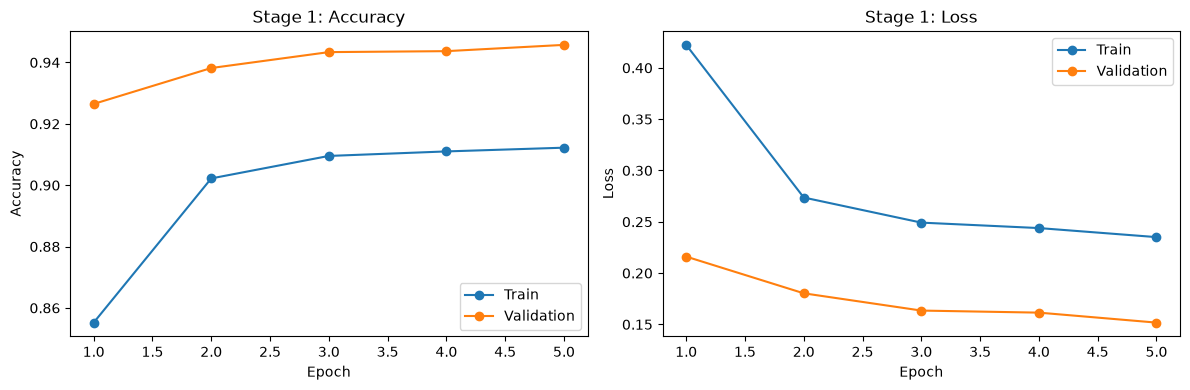

In [9]:
import pandas as pd
import matplotlib.pyplot as plt

os.makedirs("../figures", exist_ok=True)
log = pd.read_csv("../models/stage1_log.csv")
epochs = log["epoch"] + 1

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(epochs, log["accuracy"], marker="o", label="Train")
axes[0].plot(epochs, log["val_accuracy"], marker="o", label="Validation")
axes[0].set_title("Stage 1: Accuracy")
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Accuracy"); axes[0].legend()

axes[1].plot(epochs, log["loss"], marker="o", label="Train")
axes[1].plot(epochs, log["val_loss"], marker="o", label="Validation")
axes[1].set_title("Stage 1: Loss")
axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Loss"); axes[1].legend()

plt.tight_layout()
plt.savefig("../figures/stage1_curves.png", dpi=150)
plt.show()

In [10]:
# Unfreeze only the last blocks of EfficientNetB0 (block6, block7, top conv),
# keeping BatchNorm layers frozen so their statistics stay stable
base.trainable = True
for layer in base.layers:
    in_top_blocks = layer.name.startswith(("block6", "block7", "top"))
    is_bn = isinstance(layer, tf.keras.layers.BatchNormalization)
    layer.trainable = in_top_blocks and not is_bn

# Changing trainable requires recompiling, this time with a much lower learning rate
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

trainable = sum(tf.size(w).numpy() for w in model.trainable_weights)
total = model.count_params()
print(f"Trainable params: {trainable:,} of {total:,}")

Trainable params: 3,140,132 of 4,059,819


In [11]:
callbacks2 = [
    tf.keras.callbacks.ModelCheckpoint(
        "../models/stage2_best.keras", monitor="val_accuracy",
        save_best_only=True, verbose=1),
    tf.keras.callbacks.CSVLogger("../models/stage2_log.csv"),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=3, restore_best_weights=True, verbose=1),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss", factor=0.3, patience=1, min_lr=1e-6, verbose=1),
]

history2 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=12,
    callbacks=callbacks2,
)

Epoch 1/12


/home/suemon/enge707-kaggle/venv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
I0000 00:00:1791334635.888275    2091 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_80429__.250
E0000 00:00:1791334637.178673    2091 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


1590/1592 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.9570 - loss: 0.1206

I0000 00:00:1791334684.625170    2091 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_80429__.250
E0000 00:00:1791334685.403702    2091 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


1592/1592 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.9570 - loss: 0.1205
Epoch 1: val_accuracy improved from None to 0.98288, saving model to ../models/stage2_best.keras

Epoch 1: finished saving model to ../models/stage2_best.keras
1592/1592 ━━━━━━━━━━━━━━━━━━━━ 75s 35ms/step - accuracy: 0.9570 - loss: 0.1205 - val_accuracy: 0.9829 - val_loss: 0.0492 - learning_rate: 1.0000e-04
Epoch 2/12
1591/1592 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.9799 - loss: 0.0574
Epoch 2: val_accuracy improved from 0.98288 to 0.98806, saving model to ../models/stage2_best.keras

Epoch 2: finished saving model to ../models/stage2_best.keras
1592/1592 ━━━━━━━━━━━━━━━━━━━━ 47s 29ms/step - accuracy: 0.9799 - loss: 0.0574 - val_accuracy: 0.9881 - val_loss: 0.0345 - learning_rate: 1.0000e-04
Epoch 3/12
1591/1592 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.9855 - loss: 0.0414
Epoch 3: val_accuracy improved from 0.98806 to 0.99034, saving model to ../models/stage2_best.keras

Epoch 3: finished savi

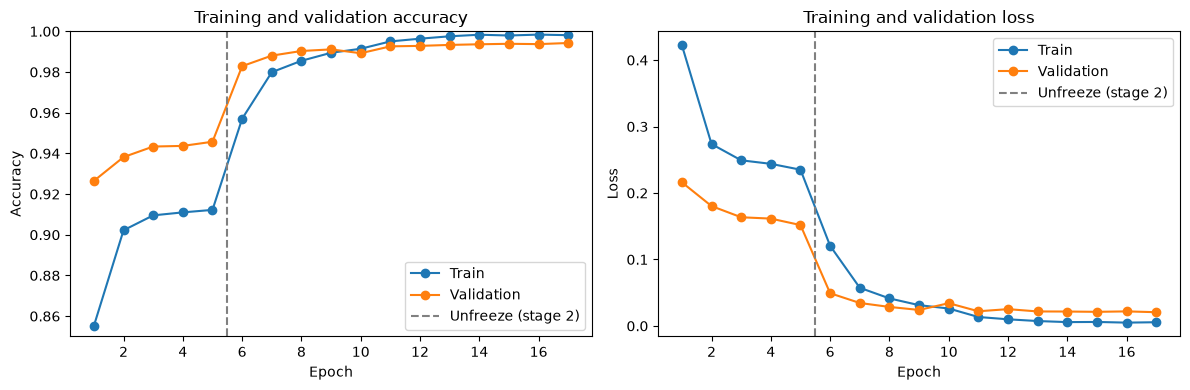

In [12]:
log1 = pd.read_csv("../models/stage1_log.csv")
log2 = pd.read_csv("../models/stage2_log.csv")
full = pd.concat([log1, log2], ignore_index=True)
epochs = range(1, len(full) + 1)
boundary = len(log1) + 0.5  # between last stage 1 and first stage 2 epoch

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, (train_col, val_col, title) in zip(
    axes,
    [("accuracy", "val_accuracy", "Accuracy"), ("loss", "val_loss", "Loss")],
):
    ax.plot(epochs, full[train_col], marker="o", label="Train")
    ax.plot(epochs, full[val_col], marker="o", label="Validation")
    ax.axvline(boundary, color="grey", linestyle="--", label="Unfreeze (stage 2)")
    ax.set_title(f"Training and validation {title.lower()}")
    ax.set_xlabel("Epoch"); ax.set_ylabel(title); ax.legend()

axes[0].set_ylim(0.85, 1.0)  # zoom so the stage 2 detail is visible

plt.tight_layout()
plt.savefig("../figures/combined_curves.png", dpi=150)
plt.show()

Validation loss: 0.0206 | Validation accuracy: 0.9943

              precision    recall  f1-score   support

      CatEye     0.9964    0.9960    0.9962      2777
     CatFace     1.0000    1.0000    1.0000      1388
    CatMouth     0.9842    0.9856    0.9849      1388
     CatNose     0.9834    0.9806    0.9820      1389
      DogEye     0.9953    0.9978    0.9966      2316
     DogFace     0.9991    1.0000    0.9996      1158
    DogMouth     0.9991    0.9965    0.9978      1158
     DogNose     0.9957    0.9948    0.9952      1158

    accuracy                         0.9943     12732
   macro avg     0.9941    0.9939    0.9940     12732
weighted avg     0.9943    0.9943    0.9943     12732



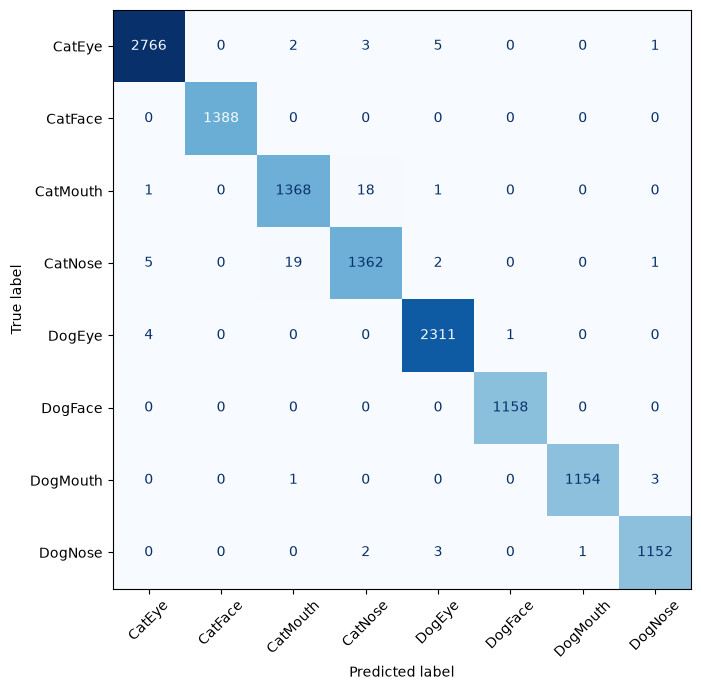

In [13]:
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

val_loss, val_acc = model.evaluate(val_ds, verbose=0)
print(f"Validation loss: {val_loss:.4f} | Validation accuracy: {val_acc:.4f}\n")

probs = model.predict(val_ds, verbose=0)
np.save("../models/val_probs.npy", probs)   # kept for misclassification analysis later
y_pred = probs.argmax(axis=1)
y_true = pipeline.val_df["label"].values    # same order as val_ds (it is not shuffled)

print(classification_report(y_true, y_pred,
                            target_names=pipeline.class_names, digits=4))

cm = confusion_matrix(y_true, y_pred)
fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay(cm, display_labels=pipeline.class_names).plot(
    ax=ax, xticks_rotation=45, cmap="Blues", colorbar=False)
plt.tight_layout()
plt.savefig("../figures/confusion_matrix.png", dpi=150)
plt.show()

In [14]:
test_ds = pipeline.make_test_dataset()
test_probs = model.predict(test_ds, verbose=1)
np.save("../models/test_probs.npy", test_probs)

submission = pd.DataFrame({
    "image_id": pipeline.test_df["image_id"].values,   # original unpadded ids, as in sample_submission
    "class": [pipeline.idx_to_class[i] for i in test_probs.argmax(axis=1)],
})
os.makedirs("../submissions", exist_ok=True)
submission.to_csv("../submissions/submission_v1_effnetb0.csv", index=False)

sample = pd.read_csv("../data/sample_submission.csv")
print("Shape:", submission.shape, "| expected:", sample.shape)
print("Columns match:", list(submission.columns) == list(sample.columns))
print("IDs match, same order:", (submission["image_id"].values == sample["image_id"].values).all())
print(submission["class"].value_counts())
submission.head()

921/921 ━━━━━━━━━━━━━━━━━━━━ 26s 24ms/step
Shape: (29443, 2) | expected: (29443, 2)
Columns match: True
IDs match, same order: True
class
CatEye      6364
DogEye      5533
CatMouth    3180
CatFace     3107
CatNose     2978
DogFace     2803
DogMouth    2751
DogNose     2727
Name: count, dtype: int64


,image_id,class
0,1,DogEye
1,2,DogMouth
2,3,DogNose
3,4,DogFace
4,5,CatMouth


In [15]:
val_conf = np.load("../models/val_probs.npy").max(axis=1)
test_conf = np.load("../models/test_probs.npy").max(axis=1)

for thr in (0.9, 0.99):
    print(f"Confidence < {thr}: val {np.mean(val_conf < thr):.2%} | test {np.mean(test_conf < thr):.2%}")
print(f"Mean confidence: val {val_conf.mean():.4f} | test {test_conf.mean():.4f}")

Confidence < 0.9: val 0.83% | test 2.29%
Confidence < 0.99: val 2.07% | test 4.52%
Mean confidence: val 0.9968 | test 0.9924


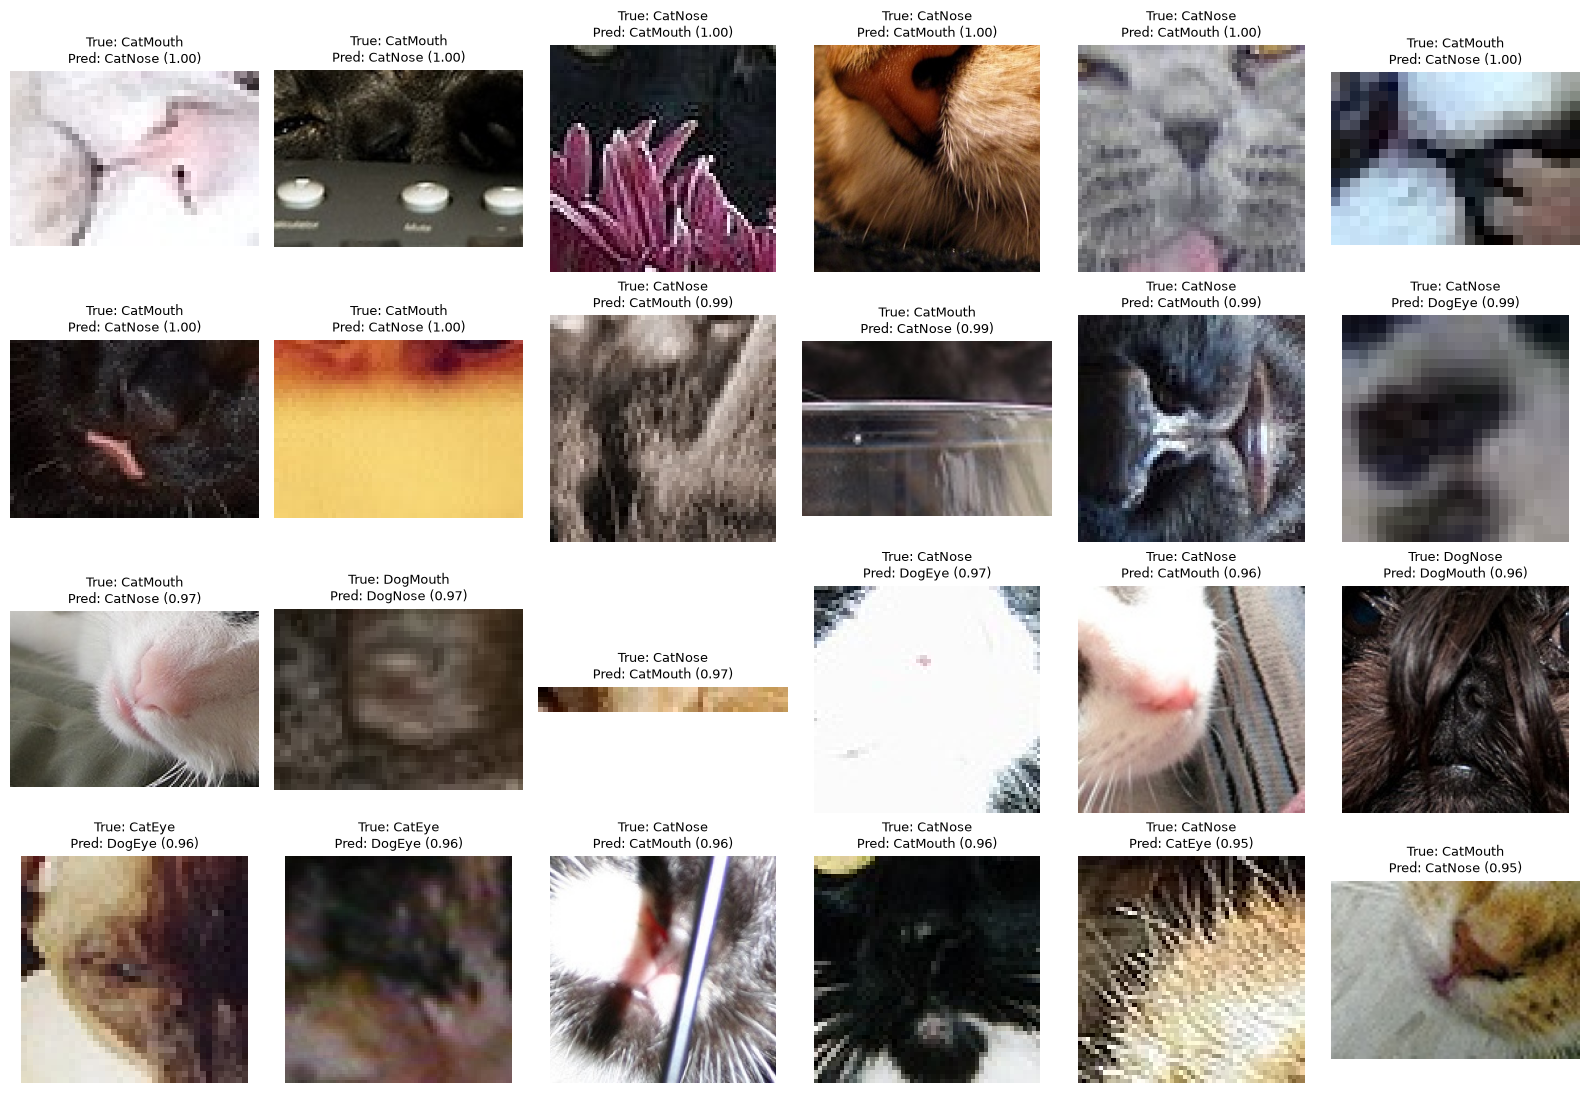

In [16]:
import matplotlib.image as mpimg

val_probs = np.load("../models/val_probs.npy")
y_pred = val_probs.argmax(axis=1)
y_true = pipeline.val_df["label"].values

wrong = np.where(y_pred != y_true)[0]
wrong = wrong[np.argsort(-val_probs[wrong].max(axis=1))][:24]   # most confident mistakes first

fig, axes = plt.subplots(4, 6, figsize=(16, 11))
for ax, i in zip(axes.ravel(), wrong):
    fname = pipeline.val_df["filename"].iloc[i]
    ax.imshow(mpimg.imread(f"{pipeline.TRAIN_DIR}/{fname}"))
    ax.set_title(f"True: {pipeline.idx_to_class[y_true[i]]}\n"
                 f"Pred: {pipeline.idx_to_class[y_pred[i]]} ({val_probs[i].max():.2f})",
                 fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.savefig("../figures/val_misclassified.png", dpi=150)
plt.show()

In [17]:
from PIL import Image

val = pipeline.val_df.copy()
val["pred"] = np.load("../models/val_probs.npy").argmax(axis=1)
val["wrong"] = val["pred"] != val["label"]

def short_side(fname):
    with Image.open(f"{pipeline.TRAIN_DIR}/{fname}") as im:
        return min(im.size)

val["short_side"] = val["filename"].apply(short_side)
val["size_bucket"] = pd.cut(val["short_side"], [0, 32, 64, 128, 256, 10000],
                            labels=["<=32", "33-64", "65-128", "129-256", ">256"])

summary = val.groupby("size_bucket", observed=True)["wrong"].agg(["count", "sum", "mean"])
summary.columns = ["images", "errors", "error_rate"]
summary["error_rate"] = (summary["error_rate"] * 100).round(2)
print(summary)

             images  errors  error_rate
size_bucket                            
<=32           1001      23        2.30
33-64          3925      27        0.69
65-128         4766      16        0.34
129-256        2324       7        0.30
>256            716       0        0.00


In [18]:
val_probs = np.load("../models/val_probs.npy")
y_true = pipeline.val_df["label"].values

val_ds_flip = pipeline.make_dataset(pipeline.val_df, shuffle=False, augment_data=False)
val_ds_flip = val_ds_flip.map(lambda x, y: (tf.image.flip_left_right(x), y))
probs_flip = model.predict(val_ds_flip, verbose=0)
probs_tta = (val_probs + probs_flip) / 2

for name, p in [("Single pass", val_probs), ("Flip TTA", probs_tta)]:
    print(f"{name}: accuracy {np.mean(p.argmax(axis=1) == y_true):.4f}")

Single pass: accuracy 0.9943
Flip TTA: accuracy 0.9943


In [19]:
from tensorflow.keras.applications import ResNet50V2

base_r50 = ResNet50V2(include_top=False, weights="imagenet",
                      input_shape=(IMG_SIZE, IMG_SIZE, 3))
base_r50.trainable = False   # stage 1: train only the new head

inputs = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
x = layers.Rescaling(scale=2.0, offset=-1.0)(inputs)   # our [0,1] -> [-1,1], what ResNet50V2 expects
x = base_r50(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)

model_r50 = models.Model(inputs, outputs)
model_r50.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
model_r50.summary()

94668760/94668760 ━━━━━━━━━━━━━━━━━━━━ 6s 0us/step


Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_3 (Rescaling)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50v2 (Functional)         │ (None, 7, 7, 2048)     │    23,564,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │        16,392 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,581,192 (89.96 MB)

 Trainable params: 16,392 (64.03 KB)

 Non-trainable params: 23,564,800 (89.89 MB)

In [20]:
callbacks_r50_s1 = [
    tf.keras.callbacks.ModelCheckpoint(
        "../models/r50_stage1_best.keras", monitor="val_accuracy",
        save_best_only=True, verbose=1),
    tf.keras.callbacks.CSVLogger("../models/r50_stage1_log.csv"),
]

history_r50_s1 = model_r50.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5,
    callbacks=callbacks_r50_s1,
)

Epoch 1/5


/home/suemon/enge707-kaggle/venv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
I0000 00:00:1791345041.890284    2092 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_230704__.165


1590/1592 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - accuracy: 0.9014 - loss: 0.2684

I0000 00:00:1791345095.133899    2093 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_230704__.165


1592/1592 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.9014 - loss: 0.2683
Epoch 1: val_accuracy improved from None to 0.95609, saving model to ../models/r50_stage1_best.keras

Epoch 1: finished saving model to ../models/r50_stage1_best.keras
1592/1592 ━━━━━━━━━━━━━━━━━━━━ 77s 42ms/step - accuracy: 0.9014 - loss: 0.2683 - val_accuracy: 0.9561 - val_loss: 0.1242
Epoch 2/5
1591/1592 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.9370 - loss: 0.1726
Epoch 2: val_accuracy improved from 0.95609 to 0.96065, saving model to ../models/r50_stage1_best.keras

Epoch 2: finished saving model to ../models/r50_stage1_best.keras
1592/1592 ━━━━━━━━━━━━━━━━━━━━ 57s 36ms/step - accuracy: 0.9370 - loss: 0.1727 - val_accuracy: 0.9607 - val_loss: 0.1119
Epoch 3/5
1592/1592 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.9417 - loss: 0.1582
Epoch 3: val_accuracy improved from 0.96065 to 0.96285, saving model to ../models/r50_stage1_best.keras

Epoch 3: finished saving model to ../models/r50_stage1_best.

In [21]:
base_r50.trainable = True
for layer in base_r50.layers:
    in_last_stage = layer.name.startswith("conv5")
    is_bn = isinstance(layer, tf.keras.layers.BatchNormalization)
    layer.trainable = in_last_stage and not is_bn

model_r50.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

trainable = sum(tf.size(w).numpy() for w in model_r50.trainable_weights)
print(f"Trainable params: {trainable:,} of {model_r50.count_params():,}")

Trainable params: 14,966,792 of 23,581,192


In [22]:
callbacks_r50_s2 = [
    tf.keras.callbacks.ModelCheckpoint(
        "../models/r50_stage2_best.keras", monitor="val_accuracy",
        save_best_only=True, verbose=1),
    tf.keras.callbacks.CSVLogger("../models/r50_stage2_log.csv"),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=3, restore_best_weights=True, verbose=1),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss", factor=0.3, patience=1, min_lr=1e-6, verbose=1),
]

history_r50_s2 = model_r50.fit(
    train_ds,
    validation_data=val_ds,
    epochs=12,
    callbacks=callbacks_r50_s2,
)

Epoch 1/12


I0000 00:00:1791345656.619019    2090 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_284887__.165


1590/1592 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - accuracy: 0.9679 - loss: 0.0943

I0000 00:00:1791345718.123366    2091 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_284887__.165


1592/1592 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - accuracy: 0.9679 - loss: 0.0943
Epoch 1: val_accuracy improved from None to 0.98178, saving model to ../models/r50_stage2_best.keras

Epoch 1: finished saving model to ../models/r50_stage2_best.keras
1592/1592 ━━━━━━━━━━━━━━━━━━━━ 84s 47ms/step - accuracy: 0.9679 - loss: 0.0943 - val_accuracy: 0.9818 - val_loss: 0.0474 - learning_rate: 1.0000e-04
Epoch 2/12
1591/1592 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - accuracy: 0.9845 - loss: 0.0467
Epoch 2: val_accuracy improved from 0.98178 to 0.98963, saving model to ../models/r50_stage2_best.keras

Epoch 2: finished saving model to ../models/r50_stage2_best.keras
1592/1592 ━━━━━━━━━━━━━━━━━━━━ 70s 44ms/step - accuracy: 0.9845 - loss: 0.0467 - val_accuracy: 0.9896 - val_loss: 0.0322 - learning_rate: 1.0000e-04
Epoch 3/12
1592/1592 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - accuracy: 0.9890 - loss: 0.0334
Epoch 3: val_accuracy did not improve from 0.98963

Epoch 3: ReduceLROnPlateau reducing learning rate to 2.

In [23]:
model_r50.save("../models/r50_final.keras")   # the restored epoch-8 weights

r50_loss, r50_acc = model_r50.evaluate(val_ds, verbose=0)
print(f"ResNet50V2 validation loss: {r50_loss:.4f} | accuracy: {r50_acc:.4f}\n")

probs_r50 = model_r50.predict(val_ds, verbose=0)
np.save("../models/val_probs_r50.npy", probs_r50)

y_true = pipeline.val_df["label"].values
probs_eff = np.load("../models/val_probs.npy")
pred_r50, pred_eff = probs_r50.argmax(axis=1), probs_eff.argmax(axis=1)
wrong_r50, wrong_eff = pred_r50 != y_true, pred_eff != y_true
print(f"EfficientNet errors: {wrong_eff.sum()} | ResNet errors: {wrong_r50.sum()} | "
      f"both wrong: {(wrong_r50 & wrong_eff).sum()}\n")

print(classification_report(y_true, pred_r50, target_names=pipeline.class_names, digits=4))

ResNet50V2 validation loss: 0.0189 | accuracy: 0.9951

EfficientNet errors: 73 | ResNet errors: 63 | both wrong: 26

              precision    recall  f1-score   support

      CatEye     0.9957    0.9978    0.9968      2777
     CatFace     1.0000    0.9986    0.9993      1388
    CatMouth     0.9906    0.9892    0.9899      1388
     CatNose     0.9849    0.9870    0.9860      1389
      DogEye     0.9961    0.9948    0.9955      2316
     DogFace     1.0000    0.9991    0.9996      1158
    DogMouth     0.9966    0.9983    0.9974      1158
     DogNose     0.9965    0.9940    0.9952      1158

    accuracy                         0.9951     12732
   macro avg     0.9951    0.9949    0.9950     12732
weighted avg     0.9951    0.9951    0.9951     12732



In [24]:
from sklearn.metrics import log_loss

probs_ens = (probs_eff + probs_r50) / 2
pred_ens = probs_ens.argmax(axis=1)

for name, p in [("EfficientNetB0", probs_eff), ("ResNet50V2", probs_r50), ("Ensemble", probs_ens)]:
    errs = (p.argmax(axis=1) != y_true).sum()
    print(f"{name:15s} accuracy {1 - errs/len(y_true):.4f} | errors {errs} | log loss {log_loss(y_true, p):.4f}")

EfficientNetB0  accuracy 0.9943 | errors 73 | log loss 0.0206
ResNet50V2      accuracy 0.9951 | errors 63 | log loss 0.0189
Ensemble        accuracy 0.9964 | errors 46 | log loss 0.0138


In [25]:
test_ds = pipeline.make_test_dataset()
test_probs_r50 = model_r50.predict(test_ds, verbose=1)
np.save("../models/test_probs_r50.npy", test_probs_r50)

test_probs_eff = np.load("../models/test_probs.npy")
test_probs_ens = (test_probs_eff + test_probs_r50) / 2

submission_v2 = pd.DataFrame({
    "image_id": pipeline.test_df["image_id"].values,
    "class": [pipeline.idx_to_class[i] for i in test_probs_ens.argmax(axis=1)],
})
submission_v2.to_csv("../submissions/submission_v2_ensemble.csv", index=False)

sample = pd.read_csv("../data/sample_submission.csv")
print("Shape:", submission_v2.shape, "| expected:", sample.shape)
print("Columns match:", list(submission_v2.columns) == list(sample.columns))
print("IDs match, same order:", (submission_v2["image_id"].values == sample["image_id"].values).all())
print(f"Agreement with v1 predictions: {np.mean(test_probs_ens.argmax(axis=1) == test_probs_eff.argmax(axis=1)):.2%}")
print(f"Test mean confidence: {test_probs_ens.max(axis=1).mean():.4f}")

921/921 ━━━━━━━━━━━━━━━━━━━━ 31s 31ms/step
Shape: (29443, 2) | expected: (29443, 2)
Columns match: True
IDs match, same order: True
Agreement with v1 predictions: 98.90%
Test mean confidence: 0.9870


In [26]:
os.makedirs("../docs", exist_ok=True)
log_md = """# Experiment log (ENGE707 Kaggle)

| # | Model / setup | Val acc | Val loss | Val errors | Kaggle public |
|---|---|---|---|---|---|
| 1 | EfficientNetB0 stage 1 (frozen, lr 1e-3, 5 epochs) | 0.9457 | 0.1517 | - | - |
| 2 | EfficientNetB0 stage 2 (top blocks unfrozen, lr 1e-4, ReduceLROnPlateau, 12 epochs) | 0.9943 | 0.0206 | 73 | 0.9767 (v1) |
| 3 | ResNet50V2 stage 1 (frozen, lr 1e-3, 5 epochs) | 0.9687 | 0.0966 | - | - |
| 4 | ResNet50V2 stage 2 (conv5 unfrozen, lr 1e-4, early stopped epoch 11, restored epoch 8) | 0.9951 | 0.0189 | 63 | not submitted |
| 5 | EfficientNetB0 + horizontal-flip TTA | 0.9943 | - | 73 | not submitted |
| 6 | Ensemble: average of #2 and #4 probabilities | 0.9964 | 0.0138 (log loss) | 46 | 0.9786 (v2) |
"""
with open("../docs/experiment_log.md", "w") as f:
    f.write(log_md)
print(open("../docs/experiment_log.md").read())

# Experiment log (ENGE707 Kaggle)

| # | Model / setup | Val acc | Val loss | Val errors | Kaggle public |
|---|---|---|---|---|---|
| 1 | EfficientNetB0 stage 1 (frozen, lr 1e-3, 5 epochs) | 0.9457 | 0.1517 | - | - |
| 2 | EfficientNetB0 stage 2 (top blocks unfrozen, lr 1e-4, ReduceLROnPlateau, 12 epochs) | 0.9943 | 0.0206 | 73 | 0.9767 (v1) |
| 3 | ResNet50V2 stage 1 (frozen, lr 1e-3, 5 epochs) | 0.9687 | 0.0966 | - | - |
| 4 | ResNet50V2 stage 2 (conv5 unfrozen, lr 1e-4, early stopped epoch 11, restored epoch 8) | 0.9951 | 0.0189 | 63 | not submitted |
| 5 | EfficientNetB0 + horizontal-flip TTA | 0.9943 | - | 73 | not submitted |
| 6 | Ensemble: average of #2 and #4 probabilities | 0.9964 | 0.0138 (log loss) | 46 | 0.9786 (v2) |



In [27]:
import sys, subprocess

out = subprocess.run([sys.executable, "-m", "pip", "freeze"],
                     capture_output=True, text=True).stdout
with open("../requirements.txt", "w") as f:
    f.write(out)

print(len(out.splitlines()), "packages written to ../requirements.txt\n")
key = ("tensorflow", "keras", "numpy", "pandas", "scikit-learn", "matplotlib", "pillow")
print("\n".join(l for l in out.splitlines() if l.split("==")[0].lower() in key))

139 packages written to ../requirements.txt

keras==3.15.1
matplotlib==3.11.2
numpy==2.5.3
pandas==3.0.6
pillow==12.3.0
scikit-learn==1.9.1
tensorflow==2.21.0


In [28]:
import os, shutil

for folder in ("models", "submissions", "figures"):
    shutil.copytree(f"../{folder}", f"../backup_run1/{folder}")

print(sorted(os.listdir("../backup_run1")))

['figures', 'models', 'submissions']


I0000 00:00:1791441472.098283     448 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1791441472.438653     448 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1791441473.747803     448 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1791441475.351562     448 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 7535 MB mem

Ensemble errors: 46 | accuracy: 0.9964

              precision    recall  f1-score   support

      CatEye     0.9982    0.9986    0.9984      2777
     CatFace     1.0000    0.9993    0.9996      1388
    CatMouth     0.9878    0.9906    0.9892      1388
     CatNose     0.9885    0.9870    0.9878      1389
      DogEye     0.9983    0.9974    0.9978      2316
     DogFace     1.0000    1.0000    1.0000      1158
    DogMouth     0.9974    0.9991    0.9983      1158
     DogNose     0.9991    0.9974    0.9983      1158

    accuracy                         0.9964     12732
   macro avg     0.9962    0.9962    0.9962     12732
weighted avg     0.9964    0.9964    0.9964     12732



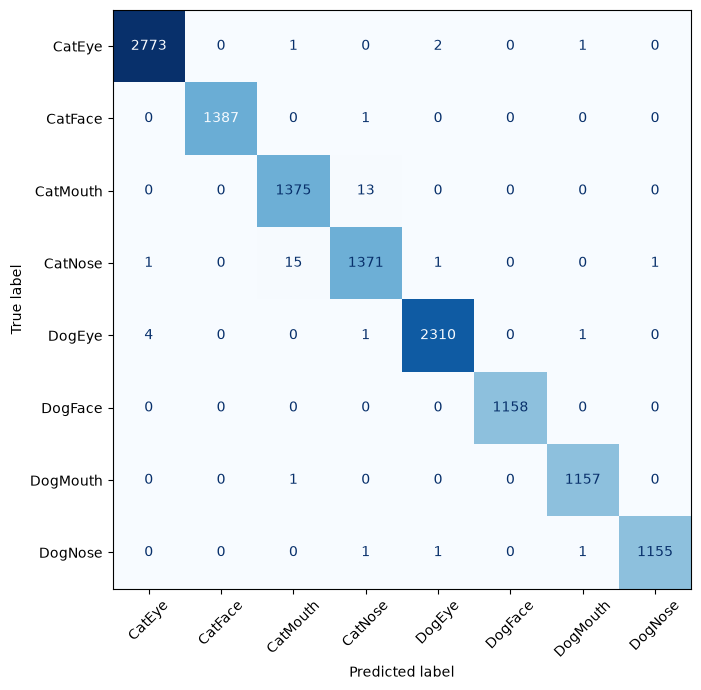

In [1]:
import sys; sys.path.append("../src")
import numpy as np, matplotlib.pyplot as plt
import pipeline
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

y_true = pipeline.val_df["label"].values
p_ens = (np.load("../models/val_probs.npy") + np.load("../models/val_probs_r50.npy")) / 2
y_pred = p_ens.argmax(axis=1)

errs = (y_pred != y_true).sum()
print(f"Ensemble errors: {errs} | accuracy: {1 - errs / len(y_true):.4f}\n")
print(classification_report(y_true, y_pred, target_names=pipeline.class_names, digits=4))

cm = confusion_matrix(y_true, y_pred)
fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay(cm, display_labels=pipeline.class_names).plot(
    ax=ax, xticks_rotation=45, cmap="Blues", colorbar=False)
plt.tight_layout()
plt.savefig("../figures/confusion_matrix_ensemble.png", dpi=150)
plt.show()

In [1]:
import sys; sys.path.append("../src")
import numpy as np, pipeline

y = pipeline.val_df["label"].values
load = lambda run, f: np.load(f"../{run}/models/{f}")
p = {"run1_eff": load("backup_run1", "val_probs.npy"), "run1_r50": load("backup_run1", "val_probs_r50.npy"),
     "run2_eff": load("backup_run2", "val_probs.npy"), "run2_r50": load("backup_run2", "val_probs_r50.npy")}
errs = lambda q: int((q.argmax(axis=1) != y).sum())

for k, q in p.items(): print(f"{k:9s} errors: {errs(q)}")
print("2-model ensemble, run 1:", errs((p["run1_eff"] + p["run1_r50"]) / 2),
      "| rerun:", errs((p["run2_eff"] + p["run2_r50"]) / 2))
e4 = sum(p.values()) / 4
print(f"4-model ensemble: {errs(e4)} errors | accuracy {1 - errs(e4) / len(y):.4f}")

I0000 00:00:1791784747.244430     613 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1791784747.599360     613 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1791784748.913485     613 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


run1_eff  errors: 73
run1_r50  errors: 63
run2_eff  errors: 75
run2_r50  errors: 75
2-model ensemble, run 1: 46 | rerun: 53
4-model ensemble: 43 errors | accuracy 0.9966


I0000 00:00:1791784750.834074     613 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 7535 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 3080, pci bus id: 0000:01:00.0, compute capability: 8.6


In [2]:
import sys; sys.path.append("../src")
import numpy as np, pandas as pd, pipeline

load = lambda run, f: np.load(f"../{run}/models/{f}")
tp = [load("backup_run1", "test_probs.npy"), load("backup_run1", "test_probs_r50.npy"),
      load("backup_run2", "test_probs.npy"), load("backup_run2", "test_probs_r50.npy")]
print("Array shapes:", [t.shape for t in tp])
t4 = sum(tp) / 4

sub = pd.DataFrame({"image_id": pipeline.test_df["image_id"].values,
                    "class": [pipeline.idx_to_class[i] for i in t4.argmax(axis=1)]})
sub.to_csv("../submissions/submission_v3_ensemble4.csv", index=False)

sample = pd.read_csv("../data/sample_submission.csv")
v2 = pd.read_csv("../submissions/submission_v2_ensemble.csv")
print("Shape:", sub.shape, "| expected:", sample.shape)
print("Columns match:", list(sub.columns) == list(sample.columns),
      "| IDs match, same order:", (sub["image_id"].values == sample["image_id"].values).all())
print(f"Predictions changed vs v2: {(sub['class'].values != v2['class'].values).sum()} of {len(sub)}")

Array shapes: [(29443, 8), (29443, 8), (29443, 8), (29443, 8)]
Shape: (29443, 2) | expected: (29443, 2)
Columns match: True | IDs match, same order: True
Predictions changed vs v2: 107 of 29443


In [3]:
path = "../docs/experiment_log.md"
lines = open(path).read().split("\n")
last_row = max(k for k, l in enumerate(lines) if l.startswith("| "))   # last table row, above the Notes paragraph
lines.insert(last_row + 1, "| 10 | Equal-weight average of 4 models: runs 1 and 2 of EfficientNetB0 and ResNet50V2 (#2, #4, #7, #8) | 0.9966 | - | 43 | 0.9790 (v3) |")
lines.append("Row 10: variance-reduction experiment (no new training). It changed 107 of 29,443 test predictions relative to v2 (row 6).")
open(path, "w").write("\n".join(lines))
print(open(path).read())

# Experiment log (ENGE707 Kaggle)

| # | Model / setup | Val acc | Val loss | Val errors | Kaggle public |
|---|---|---|---|---|---|
| 1 | EfficientNetB0 stage 1 (frozen, lr 1e-3, 5 epochs) | 0.9457 | 0.1517 | - | - |
| 2 | EfficientNetB0 stage 2 (top blocks unfrozen, lr 1e-4, ReduceLROnPlateau, 12 epochs) | 0.9943 | 0.0206 | 73 | 0.9767 (v1) |
| 3 | ResNet50V2 stage 1 (frozen, lr 1e-3, 5 epochs) | 0.9687 | 0.0966 | - | - |
| 4 | ResNet50V2 stage 2 (conv5 unfrozen, lr 1e-4, early stopped epoch 11, restored epoch 8) | 0.9951 | 0.0189 | 63 | not submitted |
| 5 | EfficientNetB0 + horizontal-flip TTA | 0.9943 | - | 73 | not submitted |
| 6 | Ensemble: average of #2 and #4 probabilities | 0.9964 | 0.0138 (log loss) | 46 | 0.9786 (v2) |
| 7 | Rerun of #2 (EfficientNetB0, identical code, seed 42 set) | 0.9941 | - | 75 | not submitted |
| 8 | Rerun of #4 (ResNet50V2, identical code, seed 42 set) | 0.9941 | - | 75 | not submitted |
| 9 | Rerun of #6 (ensemble of #7 and #8) | 0.9958 | - | 53 | 